<a href="https://colab.research.google.com/github/f0rceFOS/python-practice-algos/blob/master/636-01/hw_8_vinogradov_a_a.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip -q install kagglehub

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import precision_recall_curve, precision_score, recall_score, f1_score, auc, roc_auc_score

csv_path = Path('creditcard.csv')
if not csv_path.exists():
    csv_path = Path(kagglehub.dataset_download('mlg-ulb/creditcardfraud')) / 'creditcard.csv'

df = pd.read_csv(csv_path)
X = df.drop(columns='Class')
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()
columns = ['Time', 'Amount']
X_train[columns] = scaler.fit_transform(X_train[columns])
X_test[columns] = scaler.transform(X_test[columns])

X_normal = X_train.loc[y_train == 0]
print('Датасет:', df.shape, 'Мошеннических транзакций:', int(y.sum()))
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Мошенничество в Test:', int(y_test.sum()))

# Сложность: время O(N*d), память O(N*d), N — строки, d — признаки.

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Датасет: (284807, 31) Мошеннических транзакций: 492
Train: (227845, 30) Test: (56962, 30)
Мошенничество в Test: 98


In [3]:
contamination = 0.01
iso = IsolationForest(n_estimators=100, contamination=contamination, random_state=42, n_jobs=-1)
iso.fit(X_normal)

pred_if = (iso.predict(X_test) == -1).astype(int)
raw_if = iso.score_samples(X_test)
scores_if = -raw_if

# Сложность обучения, худший случай: время O(T*s²*d), память O(N*d + T*s*d).
# T — число деревьев, s — число объектов на дерево (по умолчанию до 256).

In [4]:
lof_train = X_normal.sample(n=min(15000, len(X_normal)), random_state=42)
lof = LocalOutlierFactor(n_neighbors=20, novelty=True, contamination=contamination, n_jobs=-1)
lof.fit(lof_train.to_numpy())

pred_lof = (lof.predict(X_test.to_numpy()) == -1).astype(int)
raw_lof = lof.score_samples(X_test.to_numpy())
scores_lof = -raw_lof
print('Нормальных транзакций для LOF:', len(lof_train))

# Сложность, худший случай: обучение O(m²*d), прогноз O(m*q*d), память O(m² + m*d).
# m — размер подвыборки Train, q — размер Test.

Нормальных транзакций для LOF: 15000


,Модель,contamination,Precision,Recall,F1,PR-AUC,ROC-AUC
0,Isolation Forest,0.01,0.0972,0.6837,0.1703,0.1680,0.9534
1,Local Outlier Factor,0.01,0.1226,0.8367,0.2138,0.6432,0.9502


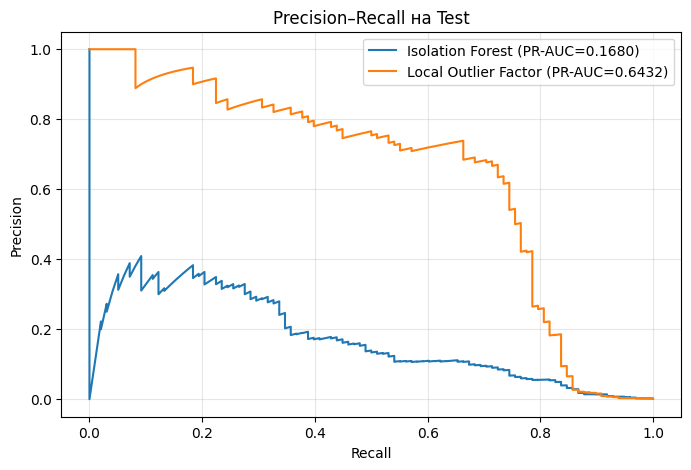

In [5]:
def calculate_metrics(name, predictions, scores, contamination):
    precision, recall, _ = precision_recall_curve(y_test, scores)
    return {
        'Модель': name,
        'contamination': contamination,
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1': f1_score(y_test, predictions, zero_division=0),
        'PR-AUC': auc(recall, precision),
        'ROC-AUC': roc_auc_score(y_test, scores)
    }, recall, precision

row_if, recall_if, precision_if = calculate_metrics('Isolation Forest', pred_if, scores_if, contamination)
row_lof, recall_lof, precision_lof = calculate_metrics('Local Outlier Factor', pred_lof, scores_lof, contamination)
results = pd.DataFrame([row_if, row_lof])
display(results.round(4))

plt.figure(figsize=(8, 5))
plt.plot(recall_if, precision_if, label=f'Isolation Forest (PR-AUC={row_if["PR-AUC"]:.4f})')
plt.plot(recall_lof, precision_lof, label=f'Local Outlier Factor (PR-AUC={row_lof["PR-AUC"]:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision–Recall на Test')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Сложность: время O(q log q), память O(q), q — количество объектов Test.

In [6]:
new_contamination = 0.001

threshold_if = np.percentile(iso.score_samples(X_normal), new_contamination * 100)
threshold_lof = np.percentile(lof.negative_outlier_factor_, new_contamination * 100)

pred_if_001 = (raw_if < threshold_if).astype(int)
pred_lof_001 = (raw_lof < threshold_lof).astype(int)

row_if_001, _, _ = calculate_metrics('Isolation Forest', pred_if_001, scores_if, new_contamination)
row_lof_001, _, _ = calculate_metrics('Local Outlier Factor', pred_lof_001, scores_lof, new_contamination)
comparison = pd.DataFrame([row_if, row_if_001, row_lof, row_lof_001])
display(comparison.round(4))

best_pr = results.loc[results['PR-AUC'].idxmax(), 'Модель']
best_f1 = results.loc[results['F1'].idxmax(), 'Модель']
print('Лучшая модель по PR-AUC:', best_pr)
print('Лучшая модель по F1:', best_f1)
print('ROC-AUC может выглядеть высоким при сильном дисбалансе: даже заметное число ложных тревог составляет малую долю от большого количества обычных транзакций. PR-AUC лучше показывает качество поиска редкого мошенничества.')

for model in ['Isolation Forest', 'Local Outlier Factor']:
    before = comparison[(comparison['Модель'] == model) & (comparison['contamination'] == 0.01)].iloc[0]
    after = comparison[(comparison['Модель'] == model) & (comparison['contamination'] == 0.001)].iloc[0]
    print(f'{model}: изменение Recall = {after["Recall"] - before["Recall"]:+.4f}, Precision = {after["Precision"] - before["Precision"]:+.4f}')

print('При уменьшении contamination срабатываний становится меньше: Recall не увеличивается, Precision может как вырасти, так и снизиться.')

# Сложность: время O(N*T*s + N log N + q), память O(N + q).

,Модель,contamination,Precision,Recall,F1,PR-AUC,ROC-AUC
0,Isolation Forest,0.010,0.0972,0.6837,0.1703,0.1680,0.9534
1,Isolation Forest,0.001,0.2929,0.2959,0.2944,0.1680,0.9534
2,Local Outlier Factor,0.010,0.1226,0.8367,0.2138,0.6432,0.9502
3,Local Outlier Factor,0.001,0.5068,0.7551,0.6066,0.6432,0.9502


Лучшая модель по PR-AUC: Local Outlier Factor
Лучшая модель по F1: Local Outlier Factor
ROC-AUC может выглядеть высоким при сильном дисбалансе: даже заметное число ложных тревог составляет малую долю от большого количества обычных транзакций. PR-AUC лучше показывает качество поиска редкого мошенничества.
Isolation Forest: изменение Recall = -0.3878, Precision = +0.1957
Local Outlier Factor: изменение Recall = -0.0816, Precision = +0.3843
При уменьшении contamination срабатываний становится меньше: Recall не увеличивается, Precision может как вырасти, так и снизиться.
